# Task 07 – Explainable AI (SHAP)

What is the purpose of Task 7? In Task 5,trained machine learning models. In Task 6, we evaluated which model performs best.

In Task 7, we try to understand why the model makes a prediction.

For example: Why did the model predict that this patient is likely to miss their appointment?

SHAP helps us understand which features influenced the prediction.

Global explanation: Which features are important for all patients?
Local explanation: Why did the model make a prediction for one patient?
Feature dependence: How does a feature affect the prediction? We will use SHAP with the Random Forest model.

# Part 01-Install and import libraries

In [ ]:
#install SHARP
!pip install shap -q

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
import joblib
import os

from google.colab import files

print("Libraries imported successfully!")

# Part 02-Load the Random Forest model and test data

Explanation:I used the Random Forest model trained in Task 5 and the test data from Task 3/5.I must explain the same model and data I actually evaluated.

Upload these files ,I used Task 7 in a new notebook:
- random_forest_model.joblib (your saved RF model — filename may differ)
- X_test.csv (your processed test features)
- y_test.csv (test target)

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving y_test.csv to y_test.csv
Saving X_test.csv to X_test.csv


In [ ]:
uploaded = files.upload()

Saving random_forest_model.joblib to random_forest_model.joblib


# Part 03-Create the SHAP explainer

Explanation: SHAP calculates how much each feature contributes to the model's prediction.I use TreeExplainer because Random Forest is a tree-based model.

In [ ]:
import joblib
import pandas as pd
import shap
import numpy as np

# 1. Load the Random Forest model and test dataset
random_forest = joblib.load('random_forest_model.joblib')
X_test = pd.read_csv('X_test.csv')

# 2. Initialize the TreeExplainer and calculate SHAP values
explainer = shap.TreeExplainer(random_forest)
shap_values = explainer.shap_values(X_test)

# Get SHAP values for class 1 (No-Show)
if isinstance(shap_values, list):
    shap_values_class1 = shap_values[1]
elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    shap_values_class1 = shap_values[:, :, 1]
else:
    shap_values_class1 = shap_values

print("SHAP values calculated successfully!")
print("Shape:", shap_values_class1.shape)

SHAP values calculated successfully!
Shape: (200, 25)


# Part 04-Global explanation (SHAP Summary Plot)

Explanation: This plot shows which features are important for predicting appointment no-shows across all test patients.
- Each dot represents a patient.
- Red indicates a high feature value.
- Blue indicates a low feature value.
- The horizontal position shows how the feature pushes the prediction.

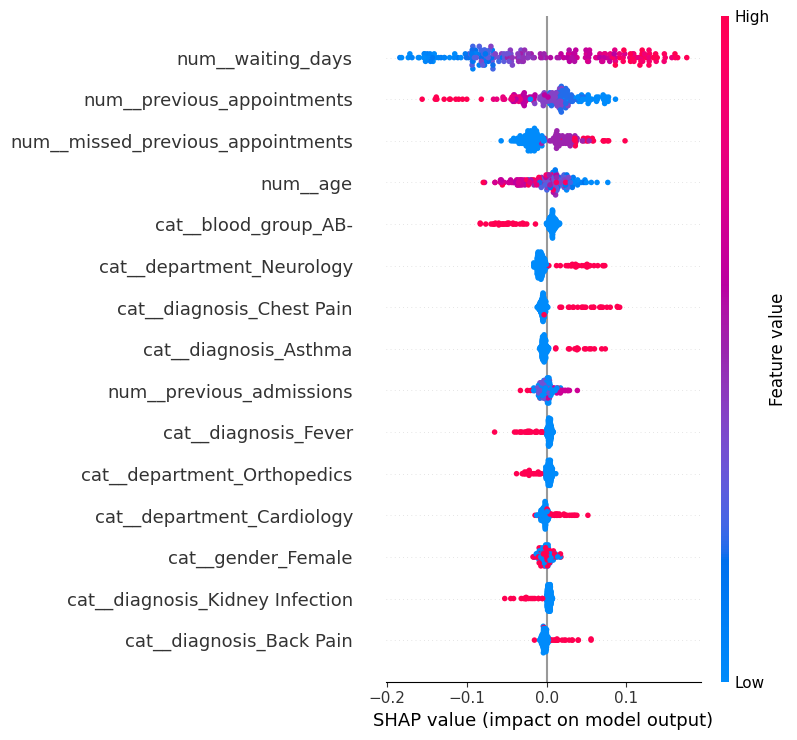

In [ ]:
shap.summary_plot(
    shap_values_class1,
    X_test,
    max_display=15
)

#Part 05-SHAP Feature Importance Bar Plot

Explanation: This chart ranks features based on their average importance across the test data. The higher the bar, the more influence that feature has on the model overall.

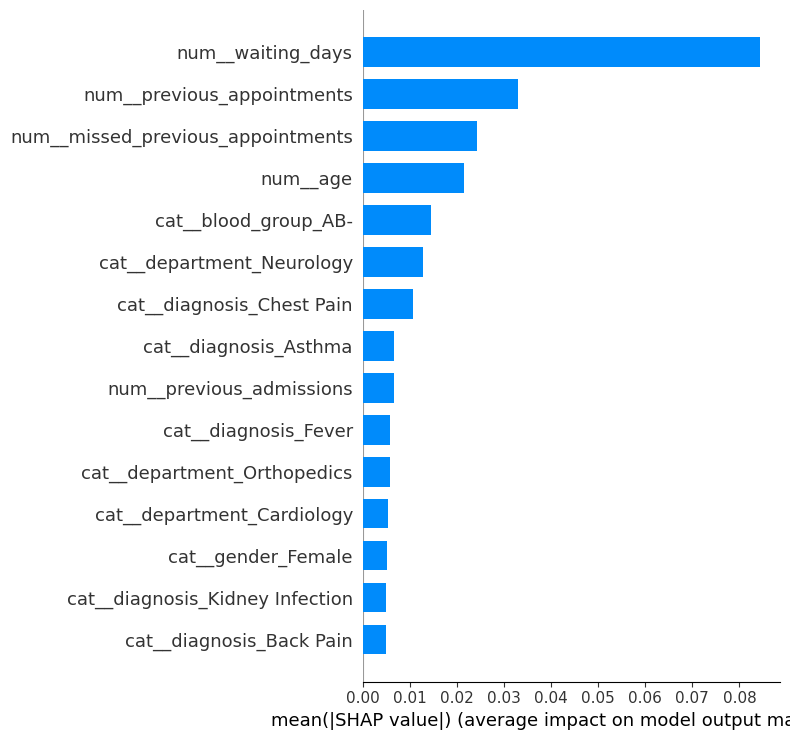

In [ ]:
shap.summary_plot(
    shap_values_class1,
    X_test,
    plot_type="bar",
    max_display=15
)

#Part 06-Local explanation (High-risk No-Show patient)

Explanation:I find one patient whom the model predicted as likely to miss the appointment and examine the factors that influenced that prediction.

In [ ]:
import pandas as pd
import numpy as np

# Load y_test since it hasn't been defined in the session yet
y_test = pd.read_csv('y_test.csv')

y_pred = random_forest.predict(X_test)
y_proba = random_forest.predict_proba(X_test)[:, 1]

# Find a correctly predicted No-Show patient
high_risk_idx = np.where((y_pred == 1) & (y_test.values.ravel() == 1))[0][0]

print("Patient index:", high_risk_idx)
print("Predicted No-Show probability:", round(y_proba[high_risk_idx], 2))

Patient index: 0
Predicted No-Show probability: 0.62


SHAP Waterfall Plot
Explanation: The waterfall plot shows how different features increase or decrease the No-Show prediction for this particular patient.
- Red features → increase predicted No-Show risk.
- Blue features → decrease predicted No-Show risk.

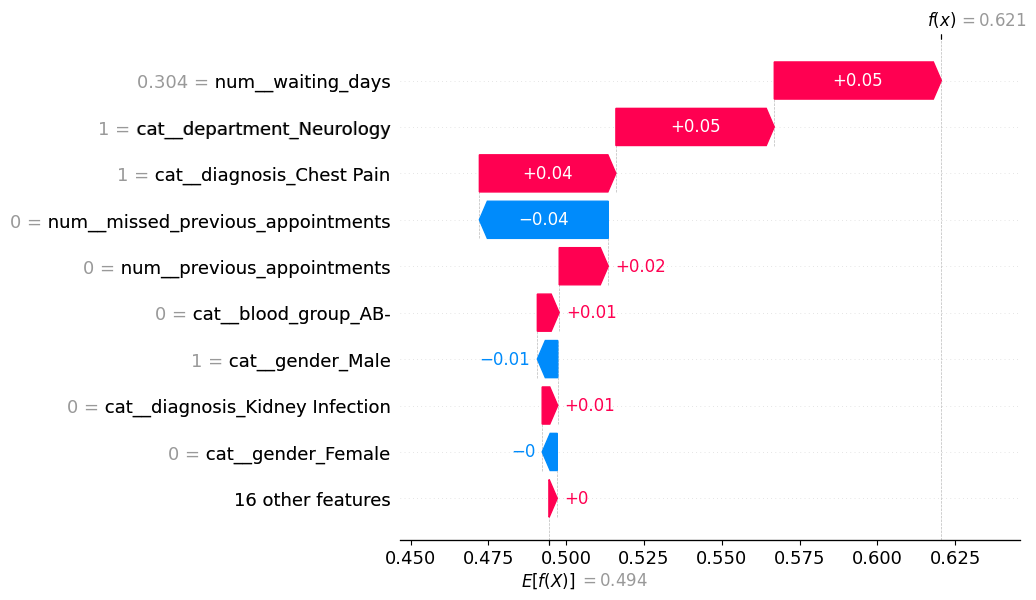

In [ ]:
expected_value = explainer.expected_value

if isinstance(expected_value, (list, np.ndarray)) and np.ndim(expected_value) > 0:
    expected_value_class1 = expected_value[1]
else:
    expected_value_class1 = expected_value

patient_explanation = shap.Explanation(
    values=shap_values_class1[high_risk_idx],
    base_values=expected_value_class1,
    data=X_test.iloc[high_risk_idx].values,
    feature_names=X_test.columns.tolist()
)

shap.plots.waterfall(patient_explanation, max_display=10)

# Part 07-Local explanation (Low-risk patient)

Explanation:I examine a patient predicted to attend the appointment (lower No-Show risk) and identify the features influencing that prediction.

In [ ]:
# Find a correctly predicted Attended/Other patient
low_risk_idx = np.where((y_pred == 0) & (y_test.values == 0))[0][0]

print("Patient index:", low_risk_idx)
print("Predicted No-Show probability:", round(y_proba[low_risk_idx], 2))

Patient index: 1
Predicted No-Show probability: 0.44


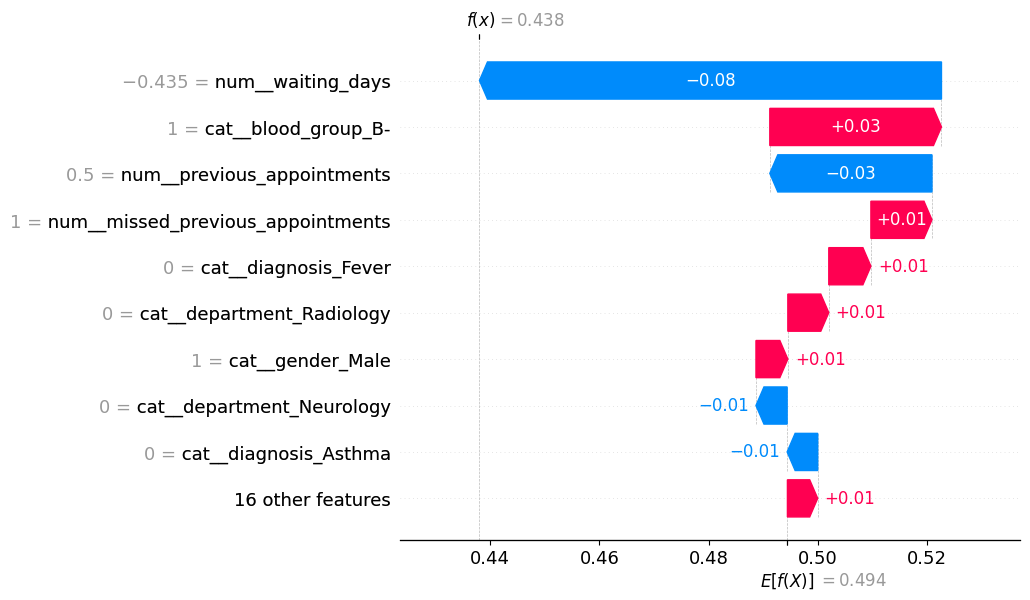

In [ ]:
patient_explanation_low = shap.Explanation(
    values=shap_values_class1[low_risk_idx],
    base_values=expected_value_class1,
    data=X_test.iloc[low_risk_idx].values,
    feature_names=X_test.columns.tolist()
)

shap.plots.waterfall(patient_explanation_low, max_display=10)

This helps me compare the features that push a prediction toward No-Show versus the features that push it away.

# Part 08-Feature Dependence Plot

Explanation: A dependence plot helps me to understand how one feature affects the No-Show prediction.

I select the most important feature automatically from the SHAP importance results.

Most important feature: num__waiting_days


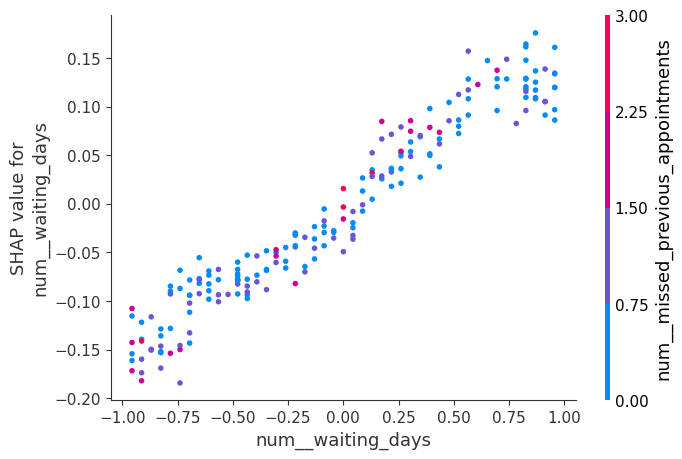

In [ ]:
mean_abs_shap = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean_Absolute_SHAP": np.abs(shap_values_class1).mean(axis=0)
}).sort_values("Mean_Absolute_SHAP", ascending=False)

top_feature = mean_abs_shap.iloc[0]["Feature"]

print("Most important feature:", top_feature)

shap.dependence_plot(
    top_feature,
    shap_values_class1,
    X_test
)

# Part 09-Save the SHAP Feature Importance Table

Explanation:I save a CSV table that ranks the features according to their average SHAP importance. This can be included in the project report.

In [ ]:
mean_abs_shap = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean_Absolute_SHAP": np.abs(shap_values_class1).mean(axis=0)
}).sort_values("Mean_Absolute_SHAP", ascending=False)

mean_abs_shap.to_csv("task07_shap_feature_importance.csv", index=False)

mean_abs_shap.head(10)

,Feature,Mean_Absolute_SHAP
1,num__waiting_days,0.084399
2,num__previous_appointments,0.033022
3,num__missed_previous_appointments,0.024241
0,num__age,0.021434
7,cat__blood_group_AB-,0.014541
14,cat__department_Neurology,0.012792
19,cat__diagnosis_Chest Pain,0.010743
17,cat__diagnosis_Asthma,0.006604
4,num__previous_admissions,0.006566
21,cat__diagnosis_Fever,0.005760


# Part 10-Discussion and Ethical Implications

### 7. Discussion: Transparency and Ethical Implications

**Important Features:** SHAP helps identify the features that influence appointment no-show predictions. Features with higher SHAP importance have a greater influence on the model's predictions. We use the generated plots to identify the most important factors.

**Prediction Reasoning:** SHAP provides explanations for individual predictions. It helps us understand why the model predicts a patient as high-risk or low-risk for missing an appointment.

**Transparency:** Explainable AI makes the model more transparent by showing which features influenced a prediction. Hospital staff can understand, review, and question model predictions instead of relying on unexplained outputs.

**Ethical Implications:**
- **Fairness:** Predictions should not unfairly disadvantage patients based on age, gender, or other characteristics.
- **Privacy:** Patient information must be protected and handled securely.
- **Human Oversight:** The model should support hospital staff decisions, not replace human judgment.
- **Limitations:** SHAP explains the model's behaviour, but it does not prove that a feature causes a patient to miss an appointment.

# Part 11-Save Task 7 outputs

In [ ]:
import os
import matplotlib.pyplot as plt

os.makedirs("task07_outputs", exist_ok=True)

# Save feature importance table
mean_abs_shap.to_csv(
    "task07_outputs/task07_shap_feature_importance.csv",
    index=False
)

# Save SHAP summary plot
shap.summary_plot(
    shap_values_class1,
    X_test,
    max_display=15,
    show=False
)
plt.savefig("task07_outputs/shap_summary_plot.png",
            bbox_inches="tight", dpi=300)
plt.close()

# Save SHAP importance bar plot
shap.summary_plot(
    shap_values_class1,
    X_test,
    plot_type="bar",
    max_display=15,
    show=False
)
plt.savefig("task07_outputs/shap_feature_importance_bar.png",
            bbox_inches="tight", dpi=300)
plt.close()

# Save high-risk patient waterfall plot
shap.plots.waterfall(patient_explanation, max_display=10, show=False)
plt.savefig("task07_outputs/high_risk_waterfall.png",
            bbox_inches="tight", dpi=300)
plt.close()

# Save low-risk patient waterfall plot
shap.plots.waterfall(patient_explanation_low, max_display=10, show=False)
plt.savefig("task07_outputs/low_risk_waterfall.png",
            bbox_inches="tight", dpi=300)
plt.close()

print("Task 07 outputs saved successfully!")

Task 07 outputs saved successfully!


#Part 12-Download the outputs as a ZIP

In [ ]:
import shutil
from google.colab import files

shutil.make_archive("Task07_XAI_Outputs", "zip", "task07_outputs")

files.download("Task07_XAI_Outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>